#### Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.utils.class_weight import compute_sample_weight
from itertools import combinations
from torch.utils.data import TensorDataset, DataLoader
from xgboost import XGBClassifier

#### Set device for later (PyTorch)

In [17]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

#### Load Data

In [18]:
df = pd.read_csv('data/KiDS_DR5_WCScut_x_DESI_DR1_columns.csv', index_col=0)
print("DF shape:", df.shape)
df.head()

DF shape: (2649271, 16)


,ID,SPECTYPE,SUBTYPE,Z,MASK,ZWARN,MAG_GAAP_u,MAG_GAAP_g,MAG_GAAP_r,MAG_GAAP_i1,MAG_GAAP_i2,MAG_GAAP_Z,MAG_GAAP_Y,MAG_GAAP_J,MAG_GAAP_H,MAG_GAAP_Ks
0,b'KiDSDR5 J083706.078+000000.11',b'QSO',b'HIZ',1.756564,0,0,20.071587,20.030886,20.716307,19.953472,20.080544,20.120974,20.126062,20.291199,20.200040,20.109331
1,b'KiDSDR5 J083756.584+000000.23',b'QSO',b'LOZ',0.709194,8,0,23.471176,22.261936,21.481810,20.796877,20.697414,20.297396,20.000948,19.687065,19.311653,18.908943
2,b'KiDSDR5 J083425.528+000002.21',b'GALAXY',NaN,0.862850,65,0,99.000000,23.785587,22.665600,21.769638,21.833502,21.017610,20.690980,20.246101,19.817320,19.443457
3,b'KiDSDR5 J083554.878+000001.11',b'STAR',b'K',0.000060,0,0,22.868792,20.338383,19.012503,18.491550,18.468970,18.168330,17.994583,17.875542,17.713032,17.989992
4,b'KiDSDR5 J083457.996+000004.19',b'STAR',b'K',0.000239,0,0,24.488472,23.819162,22.265823,21.349340,21.355482,20.829462,20.700650,20.523626,20.366919,20.444654


#### Use MASK <= 1

In [19]:
df = df[df['MASK'] <= 1].reset_index(drop=True, inplace=False)
len(df)

1947376

#### Turn missing values into np.nan

In [20]:
SENTINEL_VALUES = [-99.0, 99.0]

df = df.replace(SENTINEL_VALUES, np.nan)

#### Add target column

In [21]:
stoi = {"b'STAR'":0, "b'GALAXY'":1, "b'QSO'": 2}

df['SPECTYPE_INT'] = df['SPECTYPE'].map(lambda s: stoi[s])
TARGET = 'SPECTYPE_INT'

#### Split into train, val, test

In [22]:
idx = np.arange(df.shape[0])
train_idx, test_idx = train_test_split(idx, test_size = 0.2, random_state=42)
val_idx, test_idx = train_test_split(test_idx, test_size=0.5, random_state=42)

#### Fill missing values

In [23]:
MAGNITUDES = ['MAG_GAAP_u','MAG_GAAP_g', 'MAG_GAAP_r','MAG_GAAP_i1', 'MAG_GAAP_i2',
              'MAG_GAAP_Z', 'MAG_GAAP_Y','MAG_GAAP_J', 'MAG_GAAP_H','MAG_GAAP_Ks']

fill_values = df.loc[train_idx][MAGNITUDES].max(axis=0)

df[MAGNITUDES] = df[MAGNITUDES].fillna(fill_values)

#### Add colors (MAG_X - MAG_Y)

In [24]:
color_dict = {f"{m1.split('_')[-1]}-{m2.split('_')[-1]}": df[m1] - df[m2] for m1, m2 in combinations(MAGNITUDES, 2)}

df_only_colors = pd.DataFrame(color_dict, index=df.index)
df = pd.concat([df, df_only_colors], axis=1)

COLORS = ['u-g', 'u-r', 'u-i1', 'u-i2', 'u-Z', 'u-Y','u-J', 'u-H', 'u-Ks', 'g-r', 'g-i1', 'g-i2',
          'g-Z', 'g-Y', 'g-J', 'g-H','g-Ks', 'r-i1', 'r-i2', 'r-Z', 'r-Y', 'r-J', 'r-H', 'r-Ks', 
          'i1-i2','i1-Z', 'i1-Y', 'i1-J', 'i1-H', 'i1-Ks', 'i2-Z', 'i2-Y', 'i2-J', 'i2-H','i2-Ks', 
          'Z-Y', 'Z-J', 'Z-H', 'Z-Ks', 'Y-J', 'Y-H', 'Y-Ks', 'J-H','J-Ks', 'H-Ks']

#### Get X_, y_ datsets (train, val, test)

In [10]:
FEATURES = MAGNITUDES + COLORS
# FEATURES = COLORS
N_FEATURES = len(FEATURES)

X_train, y_train = df.loc[train_idx, FEATURES], df.loc[train_idx, TARGET]
X_val, y_val = df.loc[val_idx, FEATURES], df.loc[val_idx, TARGET]
X_test, y_test = df.loc[test_idx, FEATURES], df.loc[test_idx, TARGET]

#### Scale Features

In [11]:
scaler = MinMaxScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

#### Move (X_, y_) to PyTorch 

In [12]:
X_train_scaled_tensor, y_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32), torch.tensor(y_train.values, dtype=torch.long)
X_val_scaled_tensor, y_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32), torch.tensor(y_val.values, dtype=torch.long)
X_test_scaled_tensor, y_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32), torch.tensor(y_test.values, dtype=torch.long)

X_val_scaled_tensor, y_val_tensor = X_val_scaled_tensor.to(device), y_val_tensor.to(device)
X_test_scaled_tensor, y_test_tensor = X_test_scaled_tensor.to(device), y_test_tensor.to(device)

#### Create DataLoader

In [13]:
train_dataset = TensorDataset(X_train_scaled_tensor, y_train_tensor)
BATCH_SIZE = 512
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, pin_memory=True, num_workers=16, persistent_workers=True)

#### Create model

In [14]:
layers = []

layers.append(nn.Linear(N_FEATURES, 256))
layers.append(nn.ReLU())

for _ in range(10):
    layers.append(nn.Linear(256, 256))
    layers.append(nn.ReLU())

layers.append(nn.Linear(256, 3))

model = nn.Sequential(*layers)
model.to(device)

learning_rate = 3e-4
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

##### Loss Function

In [15]:
# Introduce classes weights to fight imbalanced dataset
class_counts = [238839, 1219423, 99638]
class_counts = torch.tensor(class_counts, dtype=torch.long, device=device)

total_samples = class_counts.sum()
n_classes = len(class_counts)
class_weights = total_samples / (n_classes * torch.sqrt(class_counts))

loss_func = nn.CrossEntropyLoss(weight=class_weights)
loss_func = nn.CrossEntropyLoss()

#### Train Loop

In [16]:
N_EPOCHS = 50

scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=3e-4, steps_per_epoch=len(train_loader), epochs=N_EPOCHS)

for i in range(N_EPOCHS):
    model.train()   
    epoch_loss = 0.0    
    
    for x, y in train_loader:
        
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        
        optimizer.zero_grad(set_to_none=True)

        preds = model(x)
        batch_loss = loss_func(preds, y)
        batch_loss.backward()
        optimizer.step()
        scheduler.step()

        epoch_loss += batch_loss.item()

    epoch_loss /= len(train_loader)

    model.eval()
    with torch.no_grad():
        val_preds = model(X_val_scaled_tensor)
        val_loss = loss_func(val_preds, y_val_tensor)

    print(f'Epoch {i}, Loss: {epoch_loss}, Val Loss: {val_loss}')

Epoch 0, Loss: 0.5295333374087214, Val Loss: 0.2831709384918213
Epoch 1, Loss: 0.2408195218482066, Val Loss: 0.18490587174892426
Epoch 2, Loss: 0.15185672787608498, Val Loss: 0.13285021483898163
Epoch 3, Loss: 0.1296981630275761, Val Loss: 0.12232964485883713
Epoch 4, Loss: 0.12412103221452123, Val Loss: 0.11738304793834686
Epoch 5, Loss: 0.12119253336369619, Val Loss: 0.11650559306144714
Epoch 6, Loss: 0.12170112436631773, Val Loss: 0.11779049038887024
Epoch 7, Loss: 0.11816022688577413, Val Loss: 0.10793279856443405
Epoch 8, Loss: 0.11255540251560482, Val Loss: 0.10605964064598083
Epoch 9, Loss: 0.10887722855766196, Val Loss: 0.10274837166070938
Epoch 10, Loss: 0.10793024289286768, Val Loss: 0.09993154555559158
Epoch 11, Loss: 0.10429866662517684, Val Loss: 0.10054837912321091
Epoch 12, Loss: 0.10056900335252383, Val Loss: 0.09567674994468689
Epoch 13, Loss: 0.09998402447659172, Val Loss: 0.0972597748041153
Epoch 14, Loss: 0.09748436780992284, Val Loss: 0.09164978563785553
Epoch 15, 

#### Calculate metrics

              precision    recall  f1-score   support

           0       0.99      0.99      0.99     29824
           1       0.98      0.99      0.99    152361
           2       0.89      0.79      0.84     12553

    accuracy                           0.98    194738
   macro avg       0.95      0.92      0.94    194738
weighted avg       0.98      0.98      0.98    194738



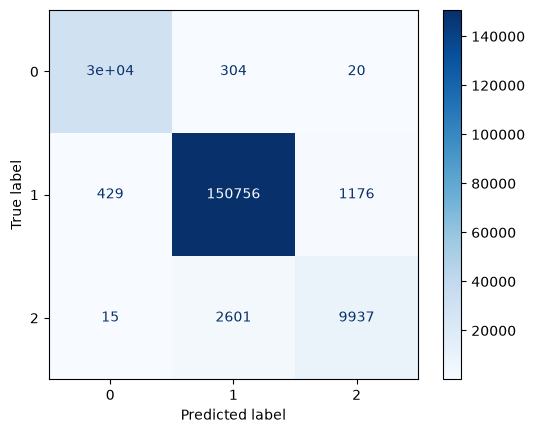

In [17]:
with torch.no_grad():
    test_preds = model(X_test_scaled_tensor)
    test_preds = torch.argmax(test_preds, axis=1)

print(classification_report(y_test_tensor.cpu(), test_preds.cpu()))

ConfusionMatrixDisplay.from_predictions(y_test_tensor.cpu(), test_preds.cpu(), cmap='Blues')
plt.show()

#### Compare with XGBoost

In [19]:
xgboost = XGBClassifier(
    max_depth=7, learning_rate=0.1, gamma=0, min_child_weight=5, colsample_bytree=0.9, subsample=0.8,
    reg_alpha=0.1, reg_lambda=1, n_estimators=100000, objective='multi:softmax',
    booster='gbtree', max_delta_step=0, colsample_bylevel=1, base_score=0.5, random_state=18235, missing=np.nan,
    verbosity=0, n_jobs=32, early_stopping_rounds=20)

In [20]:
# sample_weights = compute_sample_weight(class_weight='balanced', y=y_train)

xgboost.fit(X_train_scaled, y_train, eval_set=[(X_val_scaled, y_val)], verbose=True)

[0]	validation_0-mlogloss:0.97019
[1]	validation_0-mlogloss:0.86236
[2]	validation_0-mlogloss:0.77138
[3]	validation_0-mlogloss:0.69409
[4]	validation_0-mlogloss:0.62734
[5]	validation_0-mlogloss:0.56890
[6]	validation_0-mlogloss:0.51807
[7]	validation_0-mlogloss:0.47309
[8]	validation_0-mlogloss:0.43348
[9]	validation_0-mlogloss:0.39873
[10]	validation_0-mlogloss:0.36765
[11]	validation_0-mlogloss:0.34017
[12]	validation_0-mlogloss:0.31570
[13]	validation_0-mlogloss:0.29345
[14]	validation_0-mlogloss:0.27369
[15]	validation_0-mlogloss:0.25597
[16]	validation_0-mlogloss:0.23993
[17]	validation_0-mlogloss:0.22577
[18]	validation_0-mlogloss:0.21298
[19]	validation_0-mlogloss:0.20156
[20]	validation_0-mlogloss:0.19114
[21]	validation_0-mlogloss:0.18181
[22]	validation_0-mlogloss:0.17331
[23]	validation_0-mlogloss:0.16564
[24]	validation_0-mlogloss:0.15868
[25]	validation_0-mlogloss:0.15248
[26]	validation_0-mlogloss:0.14693
[27]	validation_0-mlogloss:0.14168
[28]	validation_0-mlogloss:0.1

,"objective objective: str | xgboost.objective.Objective | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softmax'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",0.5
,booster,'gbtree'
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,1
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.9
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",20
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg 

              precision    recall  f1-score   support

           0       0.99      0.99      0.99     29824
           1       0.98      0.99      0.99    152361
           2       0.90      0.78      0.84     12553

    accuracy                           0.98    194738
   macro avg       0.96      0.92      0.94    194738
weighted avg       0.98      0.98      0.98    194738



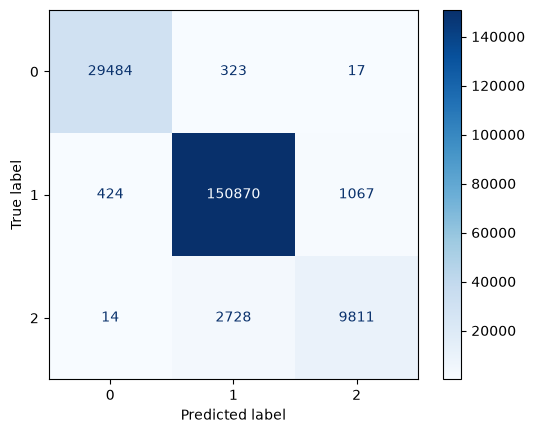

In [21]:
xgb_test_preds = xgboost.predict(X_test_scaled)
print(classification_report(y_test, xgb_test_preds))

ConfusionMatrixDisplay.from_predictions(y_test, xgb_test_preds, cmap='Blues')
plt.show()